# Exploration des données - Partie II.I (Extraction + Transformation)
Objectif : comprendre le fichier du data lake et repérer/corriger les problèmes de qualité.

In [56]:
import json, os
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Q.1 - Téléchargement

In [57]:
def download_file(url, dest_path):
    """Télécharge un fichier depuis une URL et l'enregistre sur le disque."""
    os.makedirs(os.path.dirname(dest_path), exist_ok=True)
    r = requests.get(url, timeout=60)
    r.raise_for_status()          # lève une erreur si le téléchargement échoue
    with open(dest_path, "wb") as f:
        f.write(r.content)
    return dest_path

URL = "https://dst-de.s3.eu-west-3.amazonaws.com/extract_async.json"
PATH = "data/extract_async.json"
if not os.path.exists(PATH):
    download_file(URL, PATH)

## Q.2 - Lecture et keys uniques de `employees`

In [58]:
with open(PATH, encoding="utf-8") as f:
    data = json.load(f)

print(data.keys())
employees = data["employees"]
print(len(employees), "employés")
employees[0]

dict_keys(['employees'])
50000 employés


{'id': 0,
 'personal': {'first_name': 'Лин',
  'last_name': 'Василькова',
  'email': 'линвасилькова@apple.ru',
  'country': 'Russia',
  'age': 27,
  'gender': 'F',
  'marital_status': 'Married'},
 'company': {'name': 'Apple',
  'num_employees': 154000,
  'benefits': 'Health insurance, stock options, employee discounts, paid time off, on-site fitness centers',
  'main_area_of_expertise': 'Consumer Electronics, Software',
  'headquarters': 'Cupertino, California, USA'},
 'job': {'salary': 68000,
  'department': 'Marketing',
  'join_date': '2023-07-12',
  'position_level': 'Junior',
  'performance_score': 3,
  'last_promotion_date': '2023-07-23'},
 'experience': {'experience_years': 1,
  'has_certifications': False,
  'education_level': 'PhD',
  'work_hours_per_week': 28,
  'projects_completed': 17}}

In [59]:
# keys de 1er niveau et keys imbriquées
keys = {}
for e in employees:
    for k, v in e.items():
        if isinstance(v, dict):
            keys.setdefault(k, set()).update(v.keys())
        else:
            keys.setdefault(k, set())
keys

{'id': set(),
 'personal': {'age',
  'country',
  'email',
  'first_name',
  'gender',
  'last_name',
  'marital_status'},
 'company': {'benefits',
  'headquarters',
  'main_area_of_expertise',
  'name',
  'num_employees'},
 'job': {'department',
  'join_date',
  'last_promotion_date',
  'performance_score',
  'position_level',
  'salary'},
 'experience': {'education_level',
  'experience_years',
  'has_certifications',
  'projects_completed',
  'work_hours_per_week'}}

## Q.3 - Aplatissement
On concatène les noms de keys imbriquées (`personal` + `age` -> `personal_age`) et on met `None`
quand une clé manque. Si une clé est à la fois une valeur simple et un parent, la valeur simple devient `clé*`.

In [60]:
def flatten_one(record, parent=""):
    """Aplatit un dictionnaire imbriqué : {"A": {"B": 1}} -> {"A_B": 1}"""
    flat = {}
    for k, v in record.items():
        name = f"{parent}_{k}" if parent else k
        if isinstance(v, dict):
            flat.update(flatten_one(v, name))
        else:
            flat[name] = v
    return flat

def parent_names(record, parent=""):
    """Noms des clés qui contiennent un dictionnaire."""
    names = set()
    for k, v in record.items():
        name = f"{parent}_{k}" if parent else k
        if isinstance(v, dict):
            names |= {name} | parent_names(v, name)
    return names

def flatten(records):
    parents = set().union(*(parent_names(r) for r in records))
    rows = [{(k + "*" if k in parents else k): v for k, v in flatten_one(r).items()}
            for r in records]
    columns = list(dict.fromkeys(k for row in rows for k in row))  # toutes les colonnes, ordre conservé
    return [{c: row.get(c) for c in columns} for row in rows]

# test avec l'exemple du sujet
exemple = [{"A": {"A": 0}, "B": 1}, {"B": 2, "C": 3}, {"A": 4}]
attendu = [
    {"A*": None, "A_A": 0, "B": 1, "C": None},
    {"A*": None, "A_A": None, "B": 2, "C": 3},
    {"A*": 4, "A_A": None, "B": None, "C": None},
]
assert flatten(exemple) == attendu
flat = flatten(employees)
flat[0]

{'id': 0,
 'personal_first_name': 'Лин',
 'personal_last_name': 'Василькова',
 'personal_email': 'линвасилькова@apple.ru',
 'personal_country': 'Russia',
 'personal_age': 27,
 'personal_gender': 'F',
 'personal_marital_status': 'Married',
 'company_name': 'Apple',
 'company_num_employees': 154000,
 'company_benefits': 'Health insurance, stock options, employee discounts, paid time off, on-site fitness centers',
 'company_main_area_of_expertise': 'Consumer Electronics, Software',
 'company_headquarters': 'Cupertino, California, USA',
 'job_salary': 68000,
 'job_department': 'Marketing',
 'job_join_date': '2023-07-12',
 'job_position_level': 'Junior',
 'job_performance_score': 3,
 'job_last_promotion_date': '2023-07-23',
 'experience_experience_years': 1,
 'experience_has_certifications': False,
 'experience_education_level': 'PhD',
 'experience_work_hours_per_week': 28,
 'experience_projects_completed': 17}

In [61]:
pd.DataFrame(flatten(exemple))

,A_A,B,C,A*
0,0.0,1.0,NaN,NaN
1,NaN,2.0,3.0,NaN
2,NaN,NaN,NaN,4.0


In [62]:
pd.json_normalize(exemple)

,B,A.A,C,A
0,1.0,0.0,NaN,NaN
1,2.0,NaN,3.0,NaN
2,NaN,NaN,NaN,4.0


## Q.4 - DataFrame

In [63]:
df = pd.DataFrame(flat)
df.head()

,id,personal_first_name,personal_last_name,personal_email,personal_country,personal_age,personal_gender,personal_marital_status,company_name,company_num_employees,...,job_department,job_join_date,job_position_level,job_performance_score,job_last_promotion_date,experience_experience_years,experience_has_certifications,experience_education_level,experience_work_hours_per_week,experience_projects_completed
0,0,Лин,Василькова,линвасилькова@apple.ru,Russia,27,F,Married,Apple,154000.0,...,Marketing,2023-07-12,Junior,3.0,2023-07-23,1.0,False,PhD,28.0,17.0
1,1,Gina,Schober,gina.schober@facebook.de,Germany,59,F,Divorced,Facebook,86482.0,...,Sales,2014-03-01,Mid,2.0,NaN,24.0,True,Bachelor's,42.0,23.0
2,2,Christèle,Lcq,christèlelcq@amazon.fr,France,54,F,Divorced,Amazon,1298000.0,...,HR,1992-02-29,Mid,5.0,1992-03-25,33.0,True,High School,48.0,19.0
3,3,Angeliika,Piela,angeliika.piela@apple.pl,Poland,28,F,Divorced,Apple,154000.0,...,Support,2022-09-02,Senior,5.0,2022-09-16,1.0,True,High School,60.0,50.0
4,4,Melikee,Karakılıç,,Turkey,39,F,Divorced,Microsoft,181000.0,...,HR,2013-11-13,Senior,3.0,2013-11-14,13.0,False,High School,31.0,27.0


## Q.5.1 - Colonnes

In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              50000 non-null  int64  
 1   personal_first_name             50000 non-null  str    
 2   personal_last_name              50000 non-null  str    
 3   personal_email                  50000 non-null  str    
 4   personal_country                50000 non-null  str    
 5   personal_age                    50000 non-null  int64  
 6   personal_gender                 50000 non-null  str    
 7   personal_marital_status         47937 non-null  str    
 8   company_name                    47937 non-null  str    
 9   company_num_employees           47937 non-null  float64
 10  company_benefits                47937 non-null  str    
 11  company_main_area_of_expertise  47937 non-null  str    
 12  company_headquarters            47937 non-n

## Q.5.2 - Valeurs manquantes

In [65]:
df.isna().sum()

id                                   0
personal_first_name                  0
personal_last_name                   0
personal_email                       0
personal_country                     0
personal_age                         0
personal_gender                      0
personal_marital_status           2063
company_name                      2063
company_num_employees             2063
company_benefits                  2063
company_main_area_of_expertise    2063
company_headquarters              2063
job_salary                        2063
job_department                    2063
job_join_date                     2063
job_position_level                2063
job_performance_score             2063
job_last_promotion_date           4393
experience_experience_years       2063
experience_has_certifications     2063
experience_education_level           0
experience_work_hours_per_week    2063
experience_projects_completed     2063
dtype: int64

In [66]:
# Les 2063 mêmes lignes n'ont ni entreprise, ni poste, ni expérience :
no_company = df["company_name"].isna()
print(no_company.sum(), "personnes sans entreprise")
df[no_company][["personal_email", "personal_age", "job_salary"]].head()

2063 personnes sans entreprise


,personal_email,personal_age,job_salary
65,ke.salaris@gmail.com,16,NaN
76,hhasling@hotmail.com,17,NaN
101,мирраписарева@outlook.com,0,NaN
127,승혁tracz@outlook.com,0,NaN
154,steuerberaterdespotis@outlook.com,16,NaN


**Explication** : ces personnes ne travaillent pas dans une GAFAM (emails gmail/outlook, âges très jeunes) :
elles n'ont donc ni entreprise ni salaire. Elles sont hors périmètre -> on les retire de l'analyse.

`job_last_promotion_date` manquant = l'employé n'a jamais été promu : c'est une information, on la garde à `None`.

In [67]:
df = df[~no_company].copy()
# Valeurs manquantes "cachées" : chaînes vides
(df == "").sum()[lambda s: s > 0]

personal_email                7252
personal_marital_status       2386
experience_education_level    2420
dtype: int64

In [68]:
# chaînes vides -> vraies valeurs manquantes
df = df.replace("", None)
df.isna().sum()[lambda s: s > 0]

personal_email                7252
personal_marital_status       2386
job_last_promotion_date       2330
experience_education_level    2420
dtype: int64

## Q.5.3 - Valeurs uniques

In [69]:
df.nunique().sort_values()

experience_has_certifications         2
personal_marital_status               3
job_position_level                    3
experience_education_level            4
company_main_area_of_expertise        5
company_benefits                      5
company_num_employees                 5
company_headquarters                  5
company_name                          5
job_department                        6
personal_gender                       6
job_performance_score                10
personal_country                     36
experience_work_hours_per_week       41
experience_projects_completed        51
job_salary                           70
experience_experience_years          95
personal_age                         97
job_last_promotion_date            8972
job_join_date                     10717
personal_last_name                31526
personal_first_name               34516
personal_email                    40677
id                                47937
dtype: int64

## Q.5.4 - Colonnes catégorielles

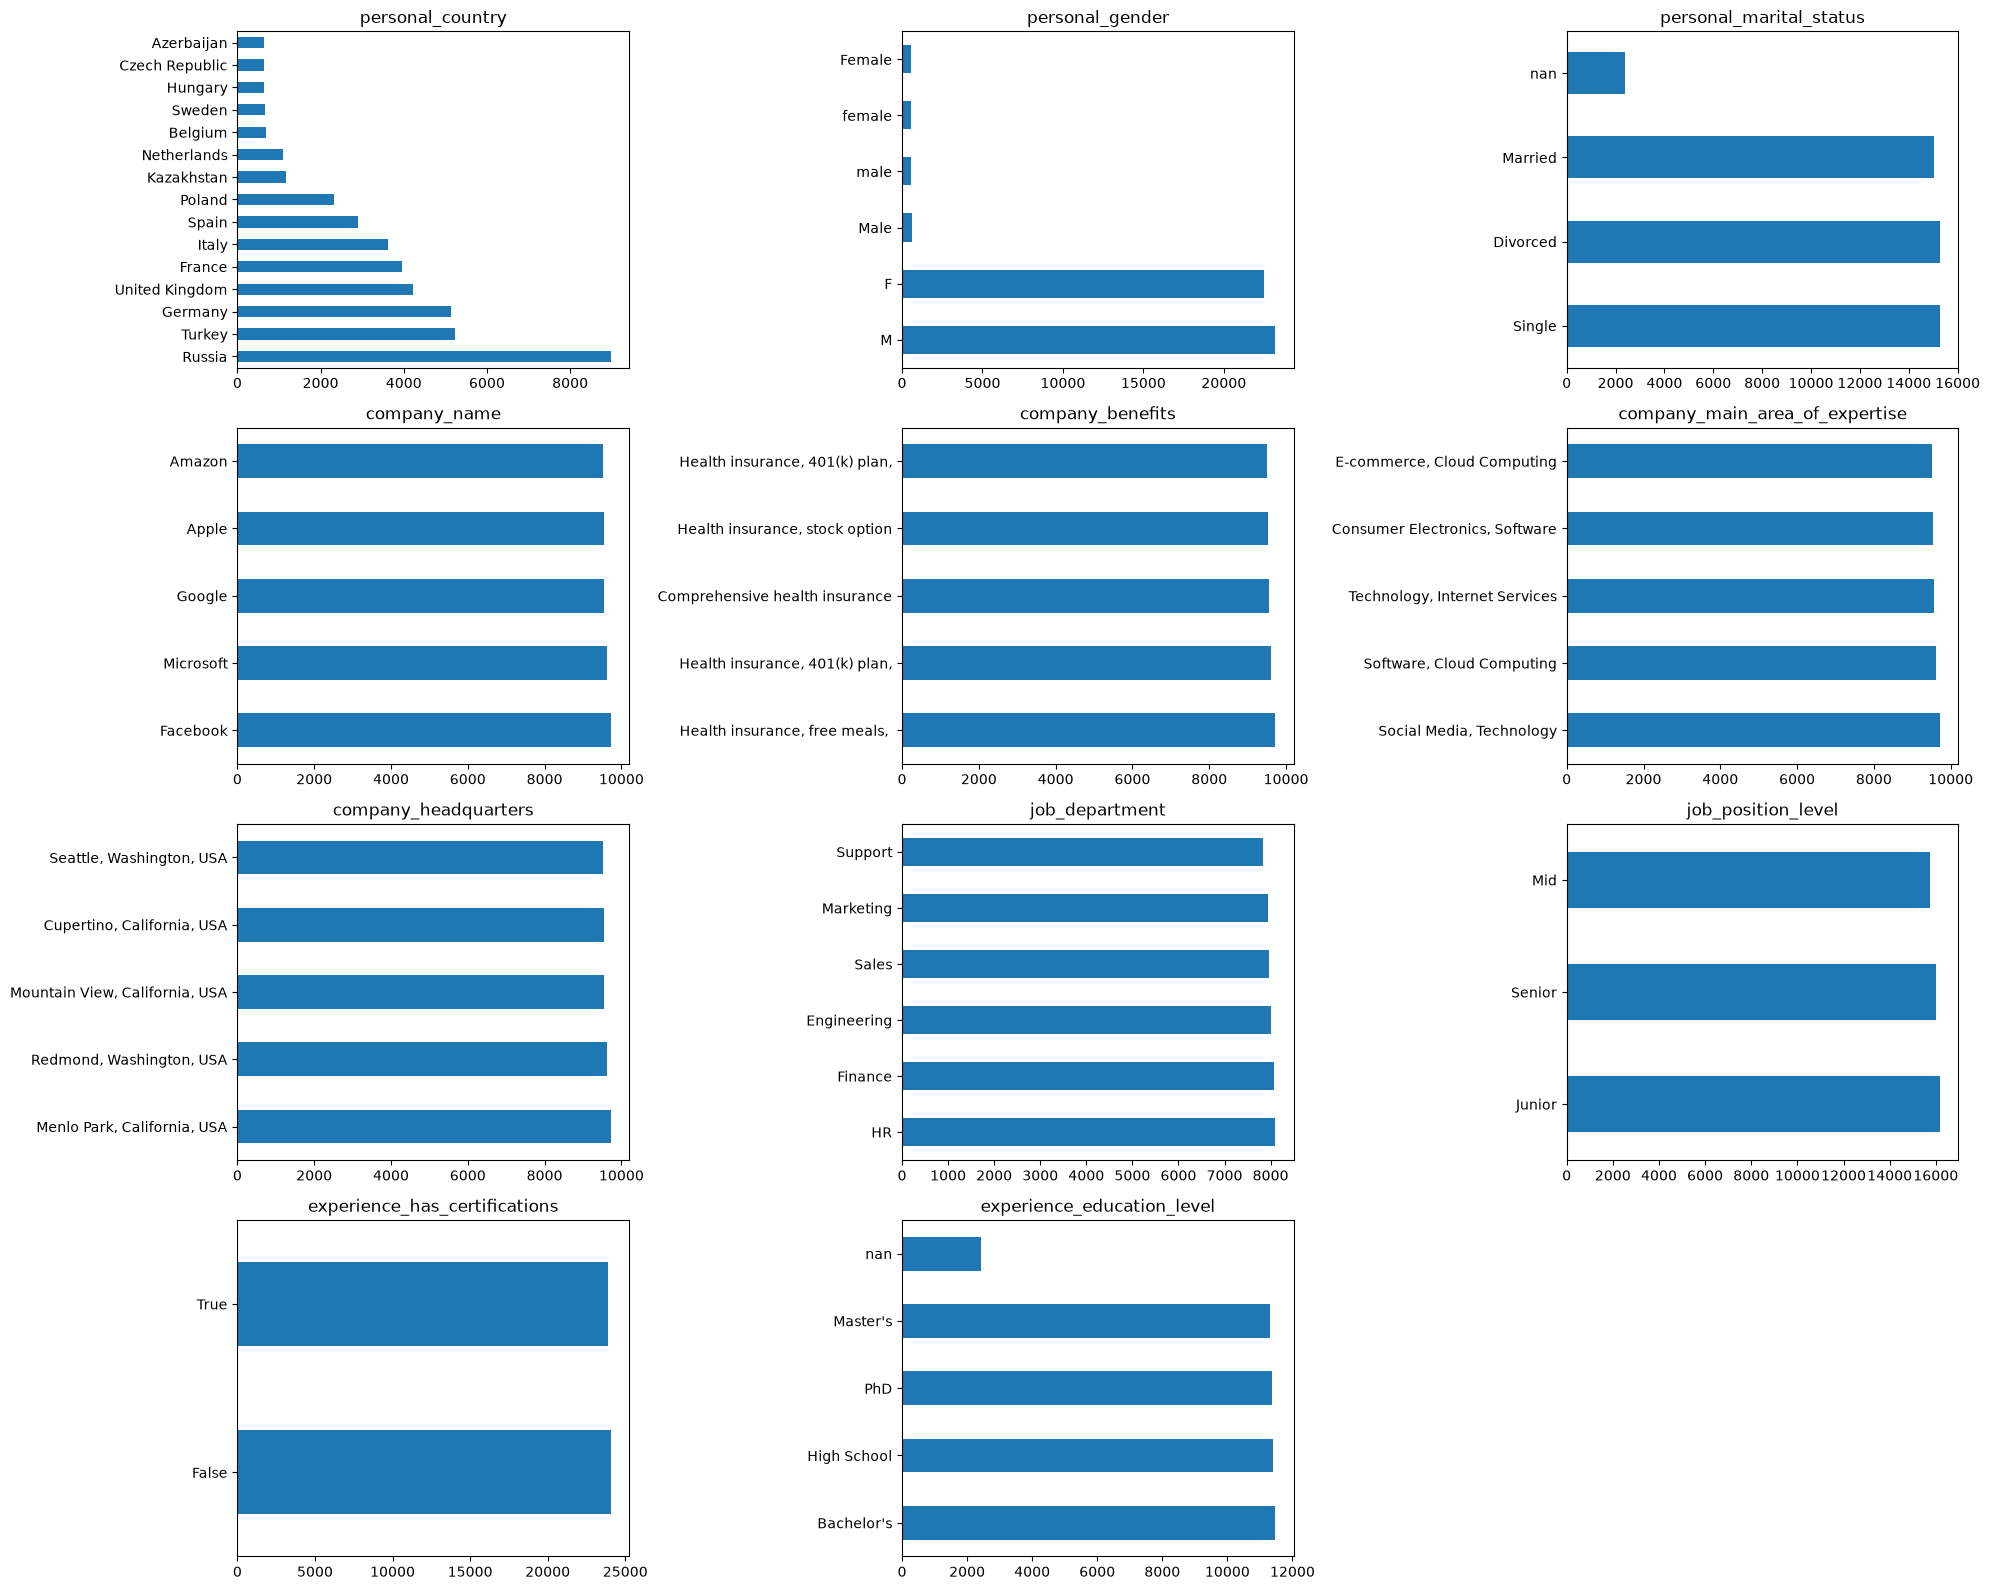

In [70]:
cat_cols = [c for c in df.columns if df[c].nunique() <= 40 and not pd.api.types.is_numeric_dtype(df[c])]
nrows = -(-len(cat_cols) // 3)   # arrondi supérieur
fig, axes = plt.subplots(nrows, 3, figsize=(20, 4 * nrows))
for ax, col in zip(axes.flat, cat_cols):
    vc = df[col].value_counts(dropna=False).head(15)
    vc.index = vc.index.astype(str).str.slice(0, 30)   # coupe les étiquettes trop longues
    vc.plot.barh(ax=ax, title=col, ylabel="")
for ax in axes.flat[len(cat_cols):]:
    ax.set_visible(False)                               # masque les cases vides
plt.tight_layout()

## Q.5.5 - Corrections
- `personal_gender` : 6 écritures (`M`, `Male`, `male`, `F`, ...) -> on normalise en `M` / `F`.
- Les colonnes `company_*` ne dépendent que du nom de l'entreprise -> elles iront dans une table à part.

In [71]:
df["personal_gender"] = df["personal_gender"].str.lower().map(
    {"m": "M", "male": "M", "f": "F", "female": "F"})
df["personal_gender"].value_counts(dropna=False)

personal_gender
M    24357
F    23580
Name: count, dtype: int64

## Q.6 - Colonnes numériques

In [72]:
num_cols = df.select_dtypes("number").columns.drop("id")
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
personal_age,47937.0,35.551724,23.498592,-65.0,26.0,39.0,52.0,65.0
company_num_employees,47937.0,373135.503098,461123.645206,86482.0,154000.0,156500.0,181000.0,1298000.0
job_salary,47937.0,74423.409892,19399.698957,0.0,70000.0,77000.0,84000.0,123000.0
job_performance_score,47937.0,5.487869,2.861925,1.0,3.0,5.0,8.0,10.0
experience_experience_years,47937.0,10.522123,11.846434,-47.0,2.0,8.0,18.0,47.0
experience_work_hours_per_week,47937.0,40.045602,11.809723,20.0,30.0,40.0,50.0,60.0
experience_projects_completed,47937.0,25.001419,14.695933,0.0,12.0,25.0,38.0,50.0


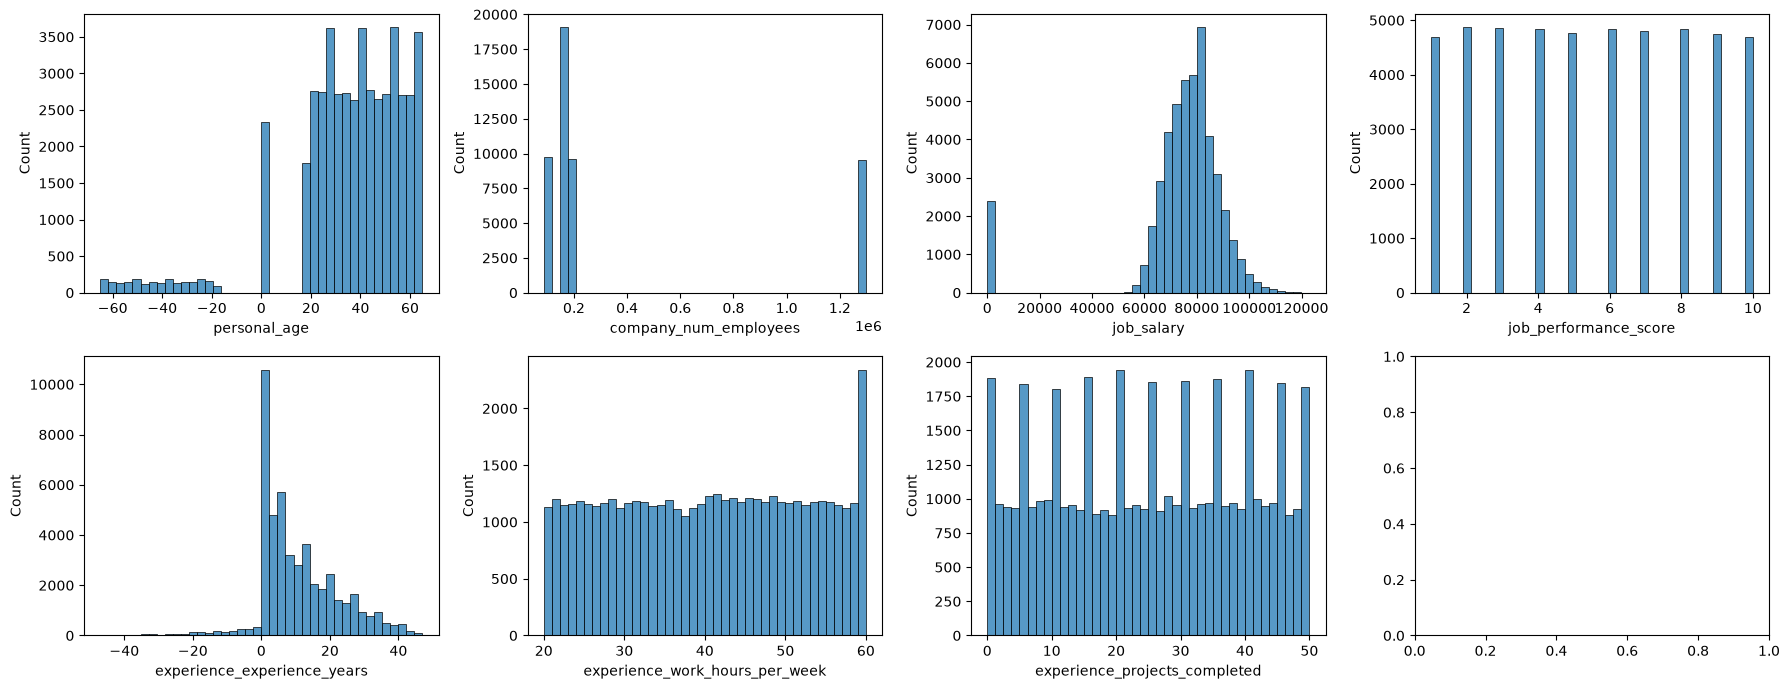

In [73]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], ax=ax, bins=40)
plt.tight_layout()

Problèmes vus :
- `personal_age` et `experience_experience_years` ont des valeurs **négatives** (miroir des positives) -> erreur de signe, on prend la valeur absolue.
- `job_salary` a un pic à **0** -> salaire inconnu, on le passe à `None`.

In [79]:
df["personal_age"] = df["personal_age"].abs()
df["experience_experience_years"] = df["experience_experience_years"].abs()
df.loc[df["job_salary"] <= 0, "job_salary"] = None
df[num_cols].describe().T[["min", "max"]]

,min,max
personal_age,0.0,65.0
company_num_employees,86482.0,1298000.0
job_salary,54000.0,123000.0
job_performance_score,1.0,10.0
experience_experience_years,0.0,47.0
experience_work_hours_per_week,20.0,60.0
experience_projects_completed,0.0,50.0


## Q.7 - Dernières vérifications

In [80]:
# Cohérence âge / expérience : on ne peut pas travailler avant ~14 ans
impossible = df["experience_experience_years"] > df["personal_age"] - 14
print(impossible.sum(), "expériences impossibles")
df.loc[impossible, "experience_experience_years"] = None

2332 expériences impossibles


In [19]:
# Dates : deux formats coexistent (YYYY-MM-DD et DD-MM-YYYY)
print(df["job_join_date"].str.match(r"\d{2}-\d{2}-\d{4}").sum(), "dates au format DD-MM-YYYY")
for col in ["job_join_date", "job_last_promotion_date"]:
    iso = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")
    fr = pd.to_datetime(df[col], format="%d-%m-%Y", errors="coerce")
    df[col] = iso.fillna(fr)
print("promotion avant l'arrivée :", (df["job_last_promotion_date"] < df["job_join_date"]).sum())
df[["job_join_date", "job_last_promotion_date"]].describe()

2371 dates au format DD-MM-YYYY
promotion avant l'arrivée : 0


,job_join_date,job_last_promotion_date
count,47937,45607
mean,2018-01-29 11:30:02.140308992,2018-02-13 10:36:49.081938944
min,1976-09-04 00:00:00,1976-09-09 00:00:00
25%,2015-07-06 00:00:00,2015-07-25 12:00:00
50%,2020-10-25 00:00:00,2020-11-05 00:00:00
75%,2023-04-10 00:00:00,2023-04-26 00:00:00
max,2024-06-05 00:00:00,2024-07-05 00:00:00


In [83]:
# Doublons
print("ids en double :", df["id"].duplicated().sum())
print("lignes identiques (hors id) :", df.drop(columns="id").duplicated().sum())

ids en double : 0
lignes identiques (hors id) : 0


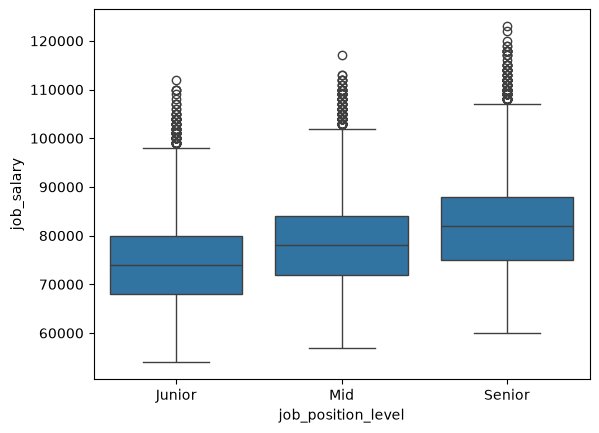

In [84]:
# Le salaire selon le niveau de poste : cohérent
sns.boxplot(data=df, x="job_position_level", y="job_salary", order=["Junior", "Mid", "Senior"]);

In [86]:
df.info()

<class 'pandas.DataFrame'>
Index: 47937 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              47937 non-null  int64  
 1   personal_first_name             47937 non-null  str    
 2   personal_last_name              47937 non-null  str    
 3   personal_email                  40685 non-null  str    
 4   personal_country                47937 non-null  str    
 5   personal_age                    47937 non-null  int64  
 6   personal_gender                 47937 non-null  str    
 7   personal_marital_status         45551 non-null  str    
 8   company_name                    47937 non-null  str    
 9   company_num_employees           47937 non-null  float64
 10  company_benefits                47937 non-null  str    
 11  company_main_area_of_expertise  47937 non-null  str    
 12  company_headquarters            47937 non-null  

Les données sont propres. Ces étapes sont reprises dans le script `etl.py`.